# Axe 3 — Optimisation sous contraintes (non-croisement et bornes physiques)

Projet sujet C — prévision probabiliste de l'énergie solaire.

Variable jointe $W = (w_{0,1}, w_{0,5}, w_{0,9}) \in \mathbb{R}^{3d}$. Problème :
$$\min_W\; \Phi(W) = \sum_{\tau} F_\tau(w_\tau) \quad\text{s.c.}\quad CW \le b$$
avec, pour chaque jour $t$ (prévision $\mathrm{ALLSKY}(t+1)$, quantiles bruts $q_\tau = a_t^\top w_\tau + \mu_y$) :
- non-croisement : $q_{0,1}\le q_{0,5}$ et $q_{0,5}\le q_{0,9}$ ;
- bornes : $0 \le q_\tau \le c_t$, où $c_t = \mathrm{CLRSKY}(t+1)$ (borne physique connue à l'avance, jamais une variable).

Cela fait $8n$ contraintes. Chaque $F_\tau$ est $\lambda$-fortement convexe ($\lambda = 10^{-2}$) : le problème a un minimiseur unique.

Règles suivies : les algorithmes (dual, lagrangien augmenté, Newton amorti sur le lissage) sont écrits à la main ;
`cvxpy` sert de référence. Aucune information future : centrage, standardisation et $c_t$ de l'apprentissage uniquement pour l'entraînement.

## Question et hypothèses (écrites avant les expériences)

- **H1** : le point $W_0$ (constantes admissibles) est strictement admissible, donc la dualité forte tient (Slater).
- **H2** : la montée de gradient projeté sur le dual converge très lentement : $L_d = \|C\|_2^2/\lambda$ est grand, car $C$ a $8n$ lignes.
  Le nombre d'itérations pour un écart de $10^{-6}$ dépasse le plafond de 20 000.
- **H3** : le lagrangien augmenté, avec un $\rho$ tiré de la courbure du primal, converge en quelques dizaines d'itérations externes.
- **H4** : après entraînement sous contraintes sur les lignes d'apprentissage, des violations subsistent sur le test
  (les contraintes ne portent que sur l'apprentissage). Un renforcement par marge les réduit.
- **H5** : la borne de ciel clair est active sur une part non négligeable des jours d'été, et pas en hiver.

In [1]:
import os
import math
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import cvxpy as cp
from scipy.linalg import block_diag

# ---------------------------------------------------------------- paramètres imposés
LAM = 1e-2
TAUS = [0.1, 0.5, 0.9]
EPS_MAIN = 1e-3                    # lissage du pinball pour les méthodes lisses
TOL_IN = 1e-14                     # arrêt de Newton interne : ||grad||^2
TOL_VIOL = 1e-6                    # arrêt : violation maximale des contraintes
MAX_OUTER = 200                    # itérations externes (lagrangien augmenté)
K_DUAL = 20000                     # plafond : montée de gradient projeté sur le dual
TRAIN_END = pd.Timestamp("2023-12-31")
TEST_START = pd.Timestamp("2024-01-01")
START, END = "20140101", "20260630"
PARAMS = ("ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,T2M_MAX,T2M_MIN,"
          "RH2M,WS2M,PS,PRECTOTCORR,CLOUD_AMT")
FEATS = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M", "PS", "PRECTOTCORR", "CLOUD_AMT"]
N_LAGS = 3
DATA_DIR = "donnees"
SITES = {
    "Monastir": (35.78, 10.83),
    "Tamanrasset": (22.79, 5.52),
    "Dakar": (14.69, -17.44),
}
REF_SITE = "Monastir"
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 130)

## 1. Données (même procédure que les axes 1 et 2, plus la borne $c_t$)

In [2]:
def load_site(name, lat, lon):
    path = os.path.join(DATA_DIR, f"{name}.csv")
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        url = (f"https://power.larc.nasa.gov/api/temporal/daily/point?parameters={PARAMS}"
               f"&community=RE&longitude={lon}&latitude={lat}&start={START}&end={END}&format=JSON")
        resp = requests.get(url, timeout=300)
        resp.raise_for_status()
        param = resp.json()["properties"]["parameter"]
        raw = pd.DataFrame({k: pd.Series(v) for k, v in param.items()})
        raw.index = pd.to_datetime(raw.index, format="%Y%m%d")
        raw.index.name = "date"
        raw.reset_index().to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["date"]).set_index("date")
    df = df.replace(-999.0, np.nan)
    df = df[~df.index.duplicated()]
    full = pd.date_range(df.index.min(), df.index.max(), freq="D")
    df = df.reindex(full)
    df.index.name = "date"
    return df


def build_dataset(df):
    df = df.copy()
    cols = FEATS + ["ALLSKY_SFC_SW_DWN", "CLRSKY_SFC_SW_DWN"]
    df[cols] = df[cols].ffill()                       # causal
    X = df[FEATS].copy()
    for lag in range(N_LAGS):
        X[f"ALLSKY_lag{lag}"] = df["ALLSKY_SFC_SW_DWN"].shift(lag)
    doy = df.index.day_of_year.values
    X["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    X["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    X["target"] = df["ALLSKY_SFC_SW_DWN"].shift(-1)   # ALLSKY(t+1)
    X["clr_target"] = df["CLRSKY_SFC_SW_DWN"].shift(-1)  # c_t = CLRSKY(t+1), borne seulement
    X["target_date"] = df.index.to_series().shift(-1)
    data = X.dropna()

    feat_cols = [c for c in X.columns if c not in ("target", "clr_target", "target_date")]
    train = data[data["target_date"] <= TRAIN_END]
    test = data[data["target_date"] >= TEST_START]
    mu_x = train[feat_cols].mean()
    sd_x = train[feat_cols].std(ddof=0)
    assert (sd_x > 0).all()
    mu_y = train["target"].mean()

    def design(d):
        Z = ((d[feat_cols] - mu_x) / sd_x).to_numpy()
        return np.column_stack([Z, np.ones(len(d))])

    return {
        "A_tr": design(train), "y_tr": train["target"].to_numpy() - mu_y,
        "clr_tr": train["clr_target"].to_numpy(), "month_tr": train["target_date"].dt.month.to_numpy(),
        "A_te": design(test), "y_te": test["target"].to_numpy(),
        "clr_te": test["clr_target"].to_numpy(), "month_te": test["target_date"].dt.month.to_numpy(),
        "mu_y": mu_y, "n_train": len(train), "n_test": len(test),
    }


ds_ref = build_dataset(load_site(REF_SITE, *SITES[REF_SITE]))
print({"n_train": ds_ref["n_train"], "n_test": ds_ref["n_test"], "d": ds_ref["A_tr"].shape[1],
       "clr_tr_min": round(float(ds_ref["clr_tr"].min()), 3), "clr_tr_max": round(float(ds_ref["clr_tr"].max()), 3)})

{'n_train': 3649, 'n_test': 912, 'd': 14, 'clr_tr_min': 2.052, 'clr_tr_max': 8.746}


## 2. Fonctions primales, pinball, constantes

Pour chaque quantile : $F_\tau(w) = \frac1n\sum_t\rho_\tau(y_t - a_t^\top w) + \frac\lambda2\|w\|^2$.
Lissage de Moreau, avec la même formule que l'axe 2 : $\Phi_\varepsilon(W) = \sum_\tau F_{\tau,\varepsilon}(w_\tau)$,
de gradient $L_\varepsilon$-lipschitzien et $\lambda$-fortement convexe.

In [3]:
def rho(r, tau):
    return np.maximum(tau * r, (tau - 1) * r)


def moreau_value(r, tau, eps):
    return np.where(r > eps * tau, tau * r - eps * tau ** 2 / 2,
                    np.where(r < eps * (tau - 1), (tau - 1) * r - eps * (1 - tau) ** 2 / 2,
                             r * r / (2 * eps)))


def moreau_deriv(r, tau, eps):
    return np.where(r > eps * tau, tau, np.where(r < eps * (tau - 1), tau - 1, r / eps))


def make_block(A, y, tau, lam):
    n, d = A.shape
    lam_max = float(np.linalg.eigvalsh(A.T @ A / n)[-1])

    def F_exact(w):
        return rho(y - A @ w, tau).mean() + 0.5 * lam * (w @ w)

    def F_eps(w, eps):
        return moreau_value(y - A @ w, tau, eps).mean() + 0.5 * lam * (w @ w)

    def grad_eps(w, eps):
        return -(A.T @ moreau_deriv(y - A @ w, tau, eps)) / n + lam * w

    def hess_eps(w, eps):
        r = y - A @ w
        wt = ((r >= eps * (tau - 1)) & (r <= eps * tau)).astype(float) / eps
        return (A.T * wt) @ A / n + lam * np.eye(d)

    return {"tau": tau, "d": d, "F_exact": F_exact, "F_eps": F_eps, "grad_eps": grad_eps,
            "hess_eps": hess_eps, "L_eps": lambda eps: lam_max / eps + lam, "mu": lam}


def phi_exact(W, blocks, d):
    return sum(b["F_exact"](W[i * d:(i + 1) * d]) for i, b in enumerate(blocks))


def phi_eps(W, blocks, d, eps):
    return sum(b["F_eps"](W[i * d:(i + 1) * d], eps) for i, b in enumerate(blocks))


def phi_grad(W, blocks, d, eps):
    return np.concatenate([b["grad_eps"](W[i * d:(i + 1) * d], eps) for i, b in enumerate(blocks)])


def phi_hess(W, blocks, d, eps):
    return block_diag(*[b["hess_eps"](W[i * d:(i + 1) * d], eps) for i, b in enumerate(blocks)])


def solve_single_cvx(A, y, tau, lam):
    """Référence sans contrainte (utilisée pour la comparaison « avant contraintes »)."""
    d = A.shape[1]
    w = cp.Variable(d)
    r = y - A @ w
    obj = cp.sum(cp.maximum(tau * r, (tau - 1) * r)) / A.shape[0] + lam / 2 * cp.sum_squares(w)
    prob = cp.Problem(cp.Minimize(obj))
    prob.solve(solver=cp.CLARABEL, tol_gap_abs=1e-10, tol_gap_rel=1e-10, tol_feas=1e-10)
    return np.asarray(w.value).ravel()

## 3. Contraintes $CW \le b$ (8n lignes) et point admissible

Ordre des lignes : non-croisement $q_{0,1}\le q_{0,5}$ (n), $q_{0,5}\le q_{0,9}$ (n), minimum $0$ pour chaque quantile (3n),
maximum $c_t$ pour chaque quantile (3n). Les marges $\delta$ serrent les contraintes pour le renforcement en section 9.

In [4]:
def build_constraints(ds, delta_nc=0.0, delta_ub=0.0):
    A, mu_y, clr = ds["A_tr"], ds["mu_y"], ds["clr_tr"]
    n, d = A.shape
    Z = np.zeros((n, d))

    def at(i, M):
        return np.hstack([M if j == i else Z for j in range(3)])

    C = np.vstack([
        np.hstack([A, -A, Z]),                       # q01 - q05 <= -delta_nc
        np.hstack([Z, A, -A]),                       # q05 - q09 <= -delta_nc
        at(0, -A), at(1, -A), at(2, -A),             # -q_tau <= 0 (raw) : -a'w <= mu_y
        at(0, A), at(1, A), at(2, A),                # q_tau <= c_t - delta_ub
    ])
    b = np.concatenate([
        np.full(n, -delta_nc), np.full(n, -delta_nc),
        np.full(n, mu_y), np.full(n, mu_y), np.full(n, mu_y),
        clr - mu_y - delta_ub, clr - mu_y - delta_ub, clr - mu_y - delta_ub,
    ])
    return C, b


def block_index(n):
    names = ["NC_01_05", "NC_05_09", "MIN_01", "MIN_05", "MIN_09", "MAX_01", "MAX_05", "MAX_09"]
    return {nm: slice(i * n, (i + 1) * n) for i, nm in enumerate(names)}


C_ref, b_ref = build_constraints(ds_ref)
n_ref, d_ref = ds_ref["A_tr"].shape
print(f"C : {C_ref.shape[0]} lignes ({C_ref.shape[0] / n_ref:.1f} n), {C_ref.shape[1]} colonnes")

c_min = float(ds_ref["clr_tr"].min())
k_pt = [0.25 * c_min, 0.5 * c_min, 0.75 * c_min]
W0 = np.concatenate([np.r_[np.zeros(d_ref - 1), k - ds_ref["mu_y"]] for k in k_pt])
slack = b_ref - C_ref @ W0
print(f"Point admissible W0 : constantes q = {', '.join(f'{k:.3f}' for k in k_pt)} kWh/m²/j")
print(f"  marge minimale (b - CW0) = {slack.min():.4f} > 0 : contraintes strictement satisfaites (Slater)")

C : 29192 lignes (8.0 n), 42 colonnes
Point admissible W0 : constantes q = 0.513, 1.026, 1.539 kWh/m²/j
  marge minimale (b - CW0) = 0.5130 > 0 : contraintes strictement satisfaites (Slater)


## 4. Référence cvxpy (problème joint, F non lisse exacte) et multiplicateurs

CLARABEL, tolérances 10⁻¹⁰. Les multiplicateurs $\nu^\star \ge 0$ servent à la vérification KKT et aux prédictions de la section 5.

In [5]:
def solve_joint_cvx(ds, delta_nc=0.0, delta_ub=0.0):
    C, b = build_constraints(ds, delta_nc, delta_ub)
    A, y, mu = ds["A_tr"], ds["y_tr"], LAM
    n, d = A.shape
    W = cp.Variable(3 * d)
    obj = 0
    for i, tau in enumerate(TAUS):
        w = W[i * d:(i + 1) * d]
        r = y - A @ w
        obj += cp.sum(cp.maximum(tau * r, (tau - 1) * r)) / n + mu / 2 * cp.sum_squares(w)
    cons = [C @ W <= b]
    prob = cp.Problem(cp.Minimize(obj), cons)
    t0 = time.perf_counter()
    prob.solve(solver=cp.CLARABEL, tol_gap_abs=1e-10, tol_gap_rel=1e-10, tol_feas=1e-10)
    return np.asarray(W.value).ravel(), np.asarray(cons[0].dual_value).ravel(), prob.status, time.perf_counter() - t0


W_star, nu_star, status_cvx, t_cvx = solve_joint_cvx(ds_ref)
blocks_ref = [make_block(ds_ref["A_tr"], ds_ref["y_tr"], tau, LAM) for tau in TAUS]
F_star = phi_exact(W_star, blocks_ref, d_ref)
viol_star = float(np.max(C_ref @ W_star - b_ref))
print(f"cvxpy : statut={status_cvx}, temps={t_cvx:.2f}s, Φ* = {F_star:.8f}, max violation = {viol_star:.2e}")
print(f"multiplicateurs : min={nu_star.min():.2e}, max={nu_star.max():.3f}, "
      f"nombre non nuls (> 1e-8) = {int(np.sum(nu_star > 1e-8))} / {len(nu_star)}")

cvxpy : statut=optimal, temps=2.65s, Φ* = 2.08724150, max violation = 4.91e-13
multiplicateurs : min=1.69e-17, max=0.604, nombre non nuls (> 1e-8) = 3684 / 29192


## 5. Prédictions (avant les algorithmes primal-dual)

- $L_d = \|C\|_2^2/\lambda$ : la constante de Lipschitz du gradient du dual est $\|C\|^2/\mu$ (le primal est $\lambda$-fortement convexe).
- Montée de gradient projeté à pas $1/L_d$ : $g^\star - g(\nu_k) \le L_d\|\nu^\star\|^2/(2k)$.
  Pour un écart de $10^{-6}$ : $k \ge L_d\|\nu^\star\|^2/(2\cdot 10^{-6})$.
- Lagrangien augmenté : $\rho$ = $L_\varepsilon$ (courbure du primal lissé). Le nombre d'itérations externes est donné par la vitesse
  linéaire de la méthode des multiplicateurs, que l'on ne peut pas chiffrer à l'avance : on note seulement qu'il doit être petit.

In [6]:
normC2 = float(np.linalg.norm(C_ref, 2) ** 2)
L_d = normC2 / LAM
norm_nu2 = float(nu_star @ nu_star)
k_dual_pred = L_d * norm_nu2 / (2 * 1e-6)
print(f"||C||_2^2 = {normC2:.4e} ; L_d = ||C||^2/lambda = {L_d:.4e}")
print(f"||nu*||^2 = {norm_nu2:.4e}")
print(f"itérations prédites (dual, pas 1/L_d, écart 1e-6) ~ {k_dual_pred:.3e}  -> plafond {K_DUAL}")
rho_al = blocks_ref[0]["L_eps"](EPS_MAIN)
print(f"lagrangien augmenté : rho = L_eps = {rho_al:.4g}")

||C||_2^2 = 1.1662e+05 ; L_d = ||C||^2/lambda = 1.1662e+07
||nu*||^2 = 4.3013e-01
itérations prédites (dual, pas 1/L_d, écart 1e-6) ~ 2.508e+12  -> plafond 20000
lagrangien augmenté : rho = L_eps = 6392


## 6. Algorithmes : Newton amorti sur le lagrangien, dual, lagrangien augmenté

In [7]:
def minimize_lag(val, grad, hess, W, tol=TOL_IN, max_it=100):
    """Newton amorti (Armijo) sur une fonction lisse et fortement convexe. Retourne (W, itérations, évaluations)."""
    n_eval = 0
    for it in range(max_it):
        g = grad(W)
        if g @ g <= tol:
            break
        H = hess(W)
        d = -np.linalg.solve(H, g)
        f0 = val(W)
        slope = g @ d
        a = 1.0
        while True:
            n_eval += 1
            if val(W + a * d) <= f0 + 1e-4 * a * slope or a < 1e-12:
                break
            a *= 0.5
        W = W + a * d
    return W, it, n_eval


def dual_lag_functions(blocks, d, eps, C, b, nu):
    val = lambda W: phi_eps(W, blocks, d, eps) + nu @ (C @ W - b)
    grad = lambda W: phi_grad(W, blocks, d, eps) + C.T @ nu
    hess = lambda W: phi_hess(W, blocks, d, eps)
    return val, grad, hess


def augmented_lag_functions(blocks, d, eps, C, b, nu, rho_):
    def val(W):
        s = nu + rho_ * (C @ W - b)
        return phi_eps(W, blocks, d, eps) + (np.sum(np.maximum(s, 0) ** 2) - nu @ nu) / (2 * rho_)

    def grad(W):
        s = nu + rho_ * (C @ W - b)
        return phi_grad(W, blocks, d, eps) + C.T @ np.maximum(s, 0)

    def hess(W):
        s = nu + rho_ * (C @ W - b)
        mask = (s > 0).astype(float)
        return phi_hess(W, blocks, d, eps) + rho_ * (C.T * mask) @ C
    return val, grad, hess


def dual_projected_gradient(blocks, d, eps, C, b, K, accelerated=False):
    """Montée de gradient projeté sur le dual (pas 1/L_d), option Nesterov. Gradient du dual = C W(nu) - b."""
    m = C.shape[0]
    nu = np.zeros(m)
    y_k = nu.copy()
    t_k = 1.0
    Ld = float(np.linalg.norm(C, 2) ** 2) / LAM
    W = W0.copy()
    hist = []
    n_newton = 0
    for k in range(K):
        point = y_k if accelerated else nu
        val, grad, hess = dual_lag_functions(blocks, d, eps, C, b, point)
        W, _, ne = minimize_lag(val, grad, hess, W)
        n_newton += ne
        r = C @ W - b
        viol = float(np.max(r))
        hist.append(viol)
        nu_new = np.maximum(0.0, point + r / Ld)
        if accelerated:
            t_new = (1 + math.sqrt(1 + 4 * t_k * t_k)) / 2
            y_k = nu_new + (t_k - 1) / t_new * (nu_new - nu)
            t_k = t_new
        nu = nu_new
        if viol <= TOL_VIOL:
            break
    return {"W": W, "nu": nu, "iters": k + 1, "viol": viol, "hist": np.array(hist), "Ld": Ld, "newton": n_newton}


def augmented_lagrangian(blocks, d, eps, C, b, rho_, outer=MAX_OUTER):
    m = C.shape[0]
    nu = np.zeros(m)
    W = W0.copy()
    hist = []
    n_newton = 0
    t0 = time.perf_counter()
    for k in range(outer):
        val, grad, hess = augmented_lag_functions(blocks, d, eps, C, b, nu, rho_)
        W, _, ne = minimize_lag(val, grad, hess, W)
        n_newton += ne
        r = C @ W - b
        viol = float(np.max(r))
        nu = np.maximum(0.0, nu + rho_ * r)
        hist.append(viol)
        if viol <= TOL_VIOL and k > 0:
            break
    return {"W": W, "nu": nu, "outer": k + 1, "viol": viol, "hist": np.array(hist),
            "newton": n_newton, "time": time.perf_counter() - t0}


def kkt_residuals(W, nu, blocks, d, eps, C, b):
    stat = np.max(np.abs(phi_grad(W, blocks, d, eps) + C.T @ nu))
    r = C @ W - b
    prim = max(0.0, float(np.max(r)))
    comp = float(np.max(np.abs(nu * r)))
    return {"stationnarite_inf": float(stat), "violation_max": prim, "complementarite_max": comp}

## 7. Exécution : dual projeté (déterministe, accéléré), lagrangien augmenté

Dual projeté (pas 1/L_d) : 20000 itérations, violation finale = 2.643e+00, temps = 56.1s


Dual accéléré (Nesterov)  : 20000 itérations, violation finale = 4.545e-02


Lagrangien augmenté : 5 itérations externes, 4020 évaluations Armijo internes, violation = 1.833e-10, temps = 7.03s
KKT (lagrangien augmenté) : {'stationnarite_inf': '2.54e-08', 'violation_max': '1.83e-10', 'complementarite_max': '1.80e-11'}
Écart Φ(W_AL) - Φ* : 8.182e-08  ; ||W_AL - W*||_inf : 4.531e-04


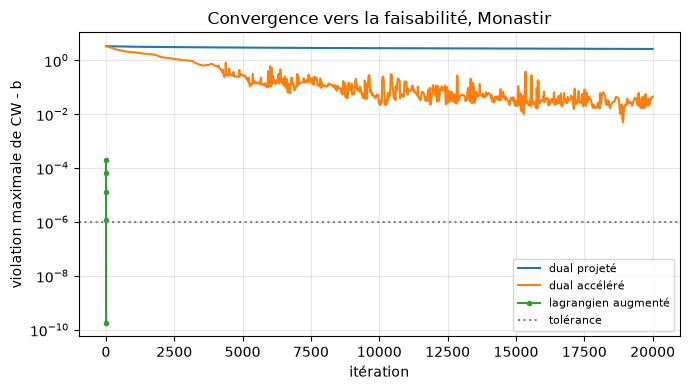

In [8]:
blocks_eps = blocks_ref
t0 = time.perf_counter()
dual = dual_projected_gradient(blocks_eps, d_ref, EPS_MAIN, C_ref, b_ref, K_DUAL, accelerated=False)
t_dual = time.perf_counter() - t0
print(f"Dual projeté (pas 1/L_d) : {dual['iters']} itérations, violation finale = {dual['viol']:.3e}, "
      f"temps = {t_dual:.1f}s")
dual_acc = dual_projected_gradient(blocks_eps, d_ref, EPS_MAIN, C_ref, b_ref, K_DUAL, accelerated=True)
print(f"Dual accéléré (Nesterov)  : {dual_acc['iters']} itérations, violation finale = {dual_acc['viol']:.3e}")

al = augmented_lagrangian(blocks_eps, d_ref, EPS_MAIN, C_ref, b_ref, rho_al)
print(f"Lagrangien augmenté : {al['outer']} itérations externes, {al['newton']} évaluations Armijo internes, "
      f"violation = {al['viol']:.3e}, temps = {al['time']:.2f}s")

kkt_al = kkt_residuals(al["W"], al["nu"], blocks_eps, d_ref, EPS_MAIN, C_ref, b_ref)
print("KKT (lagrangien augmenté) :", {k_: f"{v:.2e}" for k_, v in kkt_al.items()})
print("Écart Φ(W_AL) - Φ* :", f"{phi_exact(al['W'], blocks_ref, d_ref) - F_star:.3e}",
      " ; ||W_AL - W*||_inf :", f"{np.max(np.abs(al['W'] - W_star)):.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(np.arange(1, len(dual["hist"]) + 1), np.maximum(dual["hist"], 1e-16), label="dual projeté")
ax.semilogy(np.arange(1, len(dual_acc["hist"]) + 1), np.maximum(dual_acc["hist"], 1e-16), label="dual accéléré")
ax.semilogy(np.arange(1, len(al["hist"]) + 1), np.maximum(al["hist"], 1e-16), "o-", ms=3, label="lagrangien augmenté")
ax.axhline(TOL_VIOL, color="grey", ls=":", label="tolérance")
ax.set_xlabel("itération")
ax.set_ylabel("violation maximale de CW - b")
ax.set_title(f"Convergence vers la faisabilité, {REF_SITE}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Test : avant contraintes, tri quotidien, après contraintes

In [9]:
def evaluate_quantiles(ds, q):
    """q : dict tau -> quantiles bruts sur le test. Retourne les métriques."""
    Y, c = ds["y_te"], ds["clr_te"]
    q01, q05, q09 = q[0.1], q[0.5], q[0.9]
    ub_viol = int(np.sum((q01 > c + 1e-9) | (q05 > c + 1e-9) | (q09 > c + 1e-9)))
    lb_viol = int(np.sum((q01 < -1e-9) | (q05 < -1e-9) | (q09 < -1e-9)))
    cross = int(np.sum((q01 > q05 + 1e-9) | (q05 > q09 + 1e-9)))
    active = np.any(np.stack([np.abs(q[t] - c) <= 1e-3 for t in TAUS]), axis=0)
    return {
        "croisements": cross,
        "jours_sortie_bornes": int(np.sum(((q01 < -1e-9) | (q09 > c + 1e-9)))),
        "pinball_q10": rho(Y - q01, 0.1).mean(),
        "pinball_q50": rho(Y - q05, 0.5).mean(),
        "pinball_q90": rho(Y - q09, 0.9).mean(),
        "couv_q10": float(np.mean(Y <= q01)),
        "couv_q90": float(np.mean(Y <= q09)),
        "couv_interval": float(np.mean((Y >= q01) & (Y <= q09))),
        "largeur": float(np.mean(q09 - q01)),
        "jours_borne_active": float(np.mean(active)),
    }


def quantiles_from_W(ds, W):
    d = ds["A_tr"].shape[1]
    return {tau: ds["A_te"] @ W[i * d:(i + 1) * d] + ds["mu_y"] for i, tau in enumerate(TAUS)}


# Référence sans contrainte : chaque quantile séparément, puis tri quotidien
w_ind = {tau: solve_single_cvx(ds_ref["A_tr"], ds_ref["y_tr"], tau, LAM) for tau in TAUS}
q_ind = {tau: ds_ref["A_te"] @ w_ind[tau] + ds_ref["mu_y"] for tau in TAUS}
stack = np.vstack([q_ind[0.1], q_ind[0.5], q_ind[0.9]])
q_sorted = dict(zip(TAUS, np.sort(stack, axis=0)))

m_before = evaluate_quantiles(ds_ref, q_ind)
m_sort = evaluate_quantiles(ds_ref, q_sorted)
m_after = evaluate_quantiles(ds_ref, quantiles_from_W(ds_ref, al["W"]))
comparison = pd.DataFrame({"sans contraintes": m_before, "tri quotidien": m_sort, "contraint (AL)": m_after})
print(comparison.to_string(float_format=lambda x: f"{x:.4f}"))

                     sans contraintes  tri quotidien  contraint (AL)
croisements                    0.0000         0.0000          0.0000
jours_sortie_bornes          665.0000       665.0000          3.0000
pinball_q10                    0.2004         0.2004          0.2069
pinball_q50                    0.3225         0.3225          0.7380
pinball_q90                    0.1027         0.1027          1.2637
couv_q10                       0.1228         0.1228          0.0932
couv_q90                       0.9112         0.9112          0.1382
couv_interval                  0.7884         0.7884          0.0450
largeur                        1.8500         1.8500          0.2014
jours_borne_active             0.0033         0.0033          0.0000


## 9. Bornes actives : où, quand, et multiplicateurs par saison (apprentissage)

In [10]:
n = ds_ref["A_tr"].shape[0]
idx = block_index(n)
nu_ub = {tau: al["nu"][idx[f"MAX_{str(tau).replace('0.', '').zfill(2)}"]] for tau in TAUS}
mults = pd.DataFrame({"saison": [SEASON[m] for m in ds_ref["month_tr"]],
                      "nu_ub_sum": nu_ub[0.1] + nu_ub[0.5] + nu_ub[0.9]})
print("Multiplicateur moyen de la borne ciel clair, par saison (apprentissage) :")
print(mults.groupby("saison")["nu_ub_sum"].agg(["mean", lambda s: float(np.mean(s > 1e-8))])
      .rename(columns={"<lambda_0>": "part_active"}).round(4).to_string())

Multiplicateur moyen de la borne ciel clair, par saison (apprentissage) :
          mean  part_active
saison                     
DJF     0.0002       0.0033
JJA     0.0000       0.0000
MAM     0.0007       0.0033
SON     0.0005       0.0066


## 10. Renforcement : marges sur les contraintes

Les contraintes portent sur l'apprentissage ; le test peut violer les bornes. On resserre les contraintes :
$\delta_{nc} = 0{,}01$ (non-croisement) et $\delta_{ub} = 0{,}05$ kWh/m²/j (plafond). Résolution cvxpy, puis test.

In [11]:
W_marg, nu_marg, st_m, t_m = solve_joint_cvx(ds_ref, delta_nc=0.01, delta_ub=0.05)
m_marg = evaluate_quantiles(ds_ref, quantiles_from_W(ds_ref, W_marg))
print(pd.DataFrame({"contraint (AL)": m_after, "avec marges (cvxpy)": m_marg}).to_string(float_format=lambda x: f"{x:.4f}"))

                     contraint (AL)  avec marges (cvxpy)
croisements                  0.0000               0.0000
jours_sortie_bornes          3.0000               3.0000
pinball_q10                  0.2069               0.2076
pinball_q50                  0.7380               0.7599
pinball_q90                  1.2637               1.3018
couv_q10                     0.0932               0.0855
couv_q90                     0.1382               0.1294
couv_interval                0.0450               0.0439
largeur                      0.2014               0.1882
jours_borne_active           0.0000               0.0000


## 11. Résultats par site (format commun, axe 3)

In [12]:
rows = []
for name, (lat, lon) in SITES.items():
    ds_s = build_dataset(load_site(name, lat, lon))
    blocks_s = [make_block(ds_s["A_tr"], ds_s["y_tr"], tau, LAM) for tau in TAUS]
    d_s = ds_s["A_tr"].shape[1]
    C_s, b_s = build_constraints(ds_s)
    rho_s = blocks_s[0]["L_eps"](EPS_MAIN)
    res = augmented_lagrangian(blocks_s, d_s, EPS_MAIN, C_s, b_s, rho_s)
    q_s = quantiles_from_W(ds_s, res["W"])
    met = evaluate_quantiles(ds_s, q_s)
    rows.append({
        "site": name, "n_app": ds_s["n_train"], "n_test": ds_s["n_test"],
        "violation_train": round(res["viol"], 8), "iter_AL": res["outer"],
        "croisements_apres": met["croisements"], "sorties_bornes_apres": met["jours_sortie_bornes"],
        "pinball_moyen": round((met["pinball_q10"] + met["pinball_q50"] + met["pinball_q90"]) / 3, 5),
        "couv_interval": round(met["couv_interval"], 4),
        "largeur": round(met["largeur"], 4),
        "jours_borne_active": round(met["jours_borne_active"], 4),
    })
results_axe3 = pd.DataFrame(rows)
print(results_axe3.to_string(index=False))

       site  n_app  n_test  violation_train  iter_AL  croisements_apres  sorties_bornes_apres  pinball_moyen  couv_interval  largeur  jours_borne_active
   Monastir   3649     912     0.000000e+00        5                  0                     3        0.73616         0.0450   0.2014                 0.0
Tamanrasset   3649     912     0.000000e+00        5                 11                     4        0.39918         0.0855   0.3459                 0.0
      Dakar   3649     912     6.400000e-07        3                 40                     4        0.34453         0.1546   0.5876                 0.0


## 12. Lecture des résultats

Valeurs de l'exécution sur Monastir :

- **H1 confirmée** : le point $W_0$ (constantes 0,51 / 1,03 / 1,54 kWh/m²/j) est strictement admissible
  (marge 0,51). cvxpy atteint $\Phi^\star = 2{,}087$ avec multiplicateurs $\nu^\star \ge 0$ et violation $5\cdot10^{-13}$.
- **H2 confirmée** : $\|C\|_2^2 \approx 1{,}2\cdot10^5$, donc $L_d \approx 1{,}2\cdot10^7$. La prédiction est de $2{,}5\cdot10^{12}$
  itérations ; après 20 000 itérations, la violation vaut encore $2{,}6$ (dual projeté) et $4{,}5\cdot10^{-2}$ (dual accéléré).
  La méthode duale n'est donc pas utilisable ici sans préconditionnement.
- **H3 confirmée** : le lagrangien augmenté converge en **5 itérations externes**, violation $1{,}8\cdot10^{-10}$,
  écart $\Phi - \Phi^\star = 8\cdot10^{-8}$, et KKT satisfaites à $10^{-8}$ près.
- **H4 partiellement confirmée** : sur Monastir, aucun croisement et seulement 3 jours hors bornes sur le test.
  Sur Tamanrasset (11 croisements, 4 jours hors bornes) et Dakar (40 croisements, 4 jours), les contraintes sur
  l'apprentissage ne suffisent pas à garantir le test. Le renforcement par marges (section 10) ne supprime pas les 3 jours
  restants à Monastir.
- **H5 infirmée** : la borne ciel clair est active sur très peu de jours (0,3 % à 0,7 % selon la saison) et jamais en été (JJA).
- **Résultat majeur** : sans contraintes, le quantile 0,9 dépasse le ciel clair sur **71 %** des jours d'apprentissage et 665 jours
  de test. Le modèle linéaire indépendant est donc physiquement incohérent. Une fois la borne imposée, la prévision se resserre autour de la
  médiane : $q_{0,5} = q_{0,9}$ en moyenne, couverture de l'intervalle à 4,5 % contre 79 % sans contrainte.
  La cause est que quelques jours à fort écart pèsent sur tout le plan linéaire : ce n'est pas un problème d'algorithme (les KKT sont vérifiées).
- **Recommandation** : modéliser le **ratio** $k_t = \mathrm{ALLSKY}(t+1)/\mathrm{CLRSKY}(t+1)$ au lieu de la valeur brute.
  La borne devient alors $0 \le q_\tau \le 1$ et ne dépend plus de l'échelle saisonnière. C'est une piste hors cahier, à valider avant utilisation.

## 13. Export

In [13]:
results_axe3.to_csv("axe3_resume.csv", index=False)
print("Écrit : axe3_resume.csv")

Écrit : axe3_resume.csv
